<a href="https://colab.research.google.com/github/Krishna62186/House-Prediction-/blob/main/ML_house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing The Libraries 📚📚.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


# Lode The Dataset

In [ ]:
df = pd.read_csv(r"House Price Prediction Dataset.csv")

In [ ]:
df.head().style.background_gradient(cmap = "PuBu")

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


# Understand the Dataset 🔍
* Check basic details.

* Check for missing values.

In [ ]:
!pip install colorama -q
from colorama import Fore, Style

# Print the shape of the dataframe (number of rows and columns)
print(Fore.CYAN + "df shape: " + Style.RESET_ALL)
print(f"{df.shape}\n")

# Print basic information about the dataframe (column names, data types, non-null values)
print(Fore.GREEN + "df info: " + Style.RESET_ALL)
print(f"{df.info()}\n")

# Print the count of missing (NaN) values in each column
print(Fore.YELLOW + "df isnull sum: " + Style.RESET_ALL)
print(f"{df.isnull().sum()}\n")

# Print summary statistics for numerical columns (count, mean, std, min, max, etc.)
print(Fore.MAGENTA + "df describe: " + Style.RESET_ALL)
print(f"{df.describe()}\n")

df shape: 
(2000, 10)

df info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB
None

df isnull sum: 
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

df describe: 
                Id         Area     Bedrooms   Bathrooms       Floors  \
count  2000.000000  2000.000000  2000.000000  2000.00000  2000.0000

In [ ]:
# Dfine the numerical and categorical columns
numerical = df.select_dtypes(include=["int64"]).columns
categorical = df.select_dtypes(include=["object"]).columns

print(f" We have features: {len(numerical)} numerical features {numerical}")
print(100 * ">")
print(f" We have features: {len(categorical)} categorical features {categorical}")

 We have features: 7 numerical features Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price'], dtype='object')
>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>>
 We have features: 3 categorical features Index(['Location', 'Condition', 'Garage'], dtype='object')


# EDA 📉📊📈

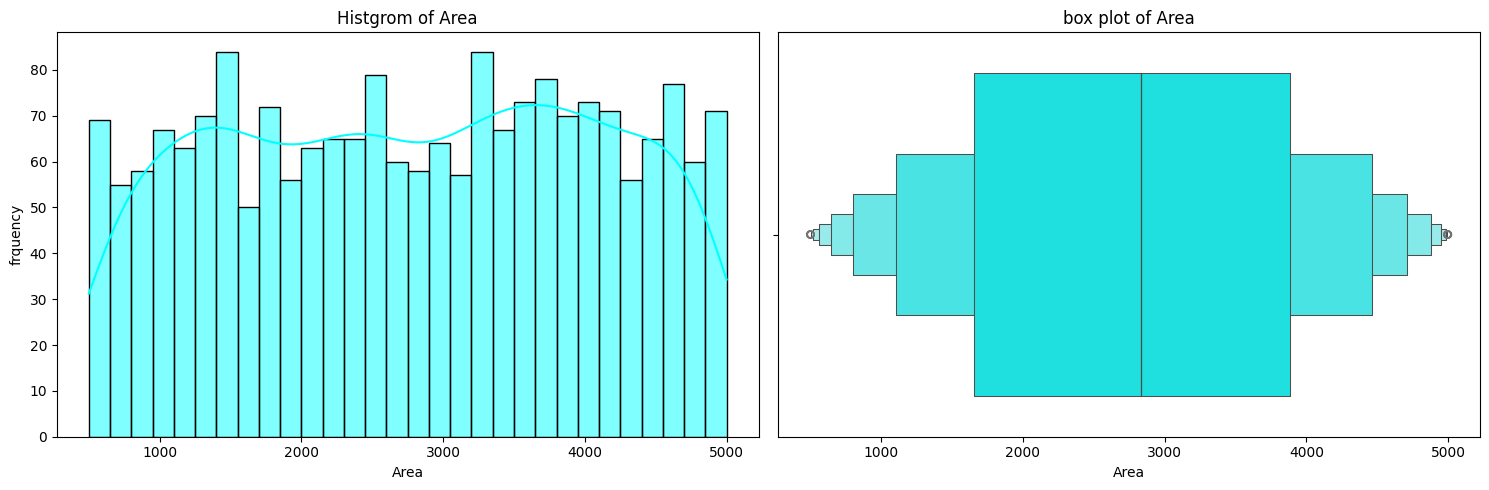

Number of Unique Area: 1622
Missing Values in Area: 0


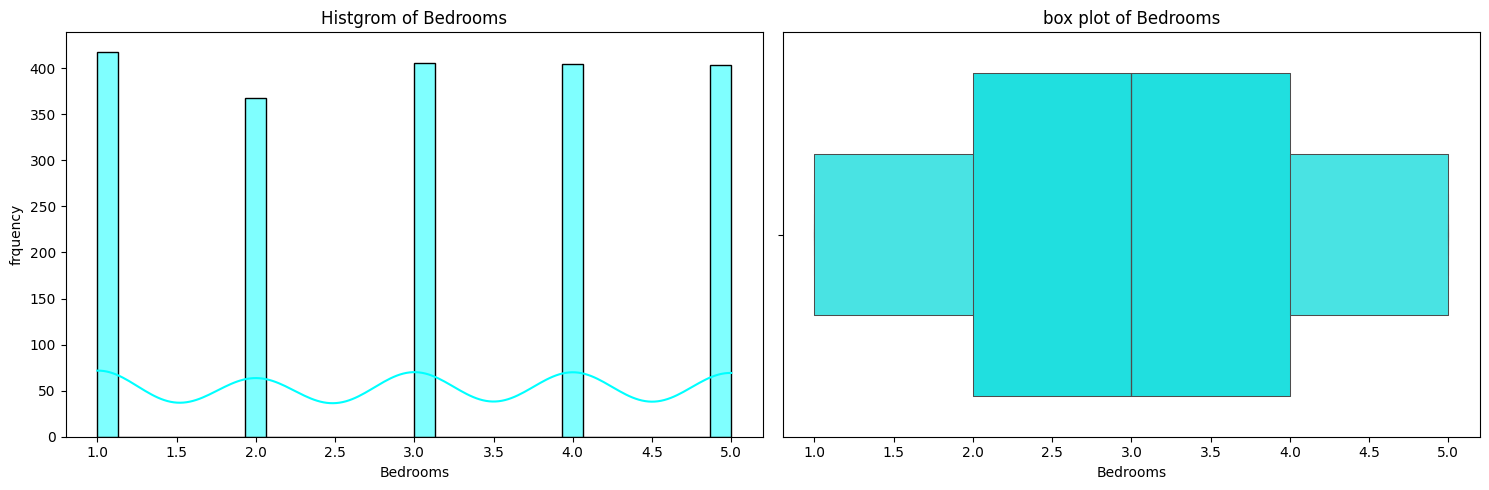

Number of Unique Bedrooms: 5
Missing Values in Bedrooms: 0


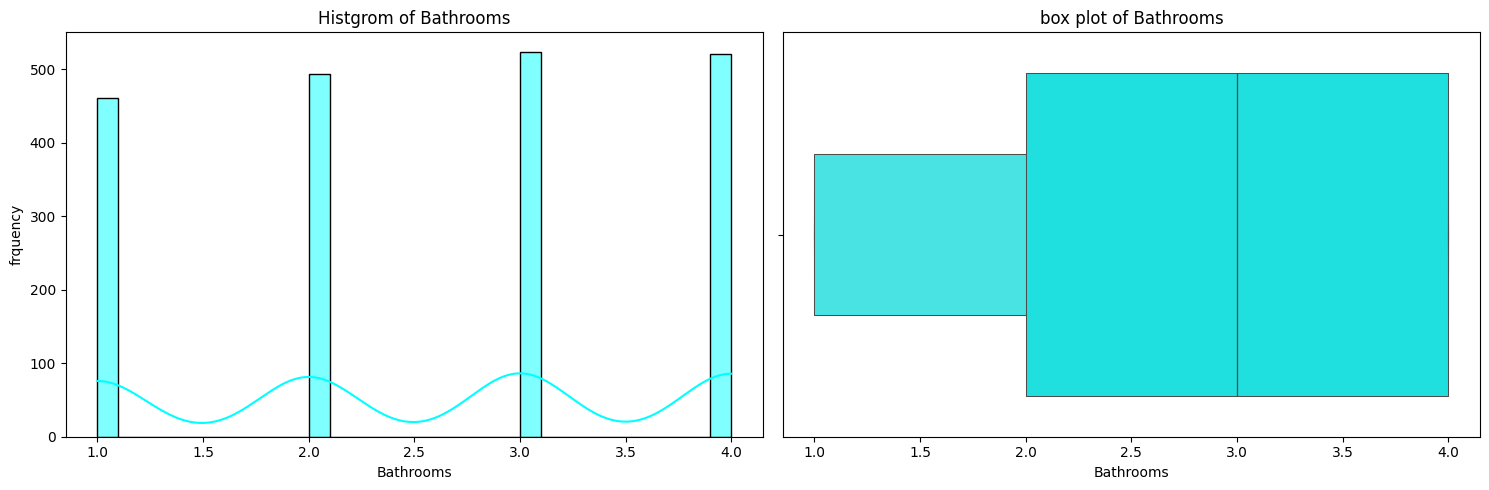

Number of Unique Bathrooms: 4
Missing Values in Bathrooms: 0


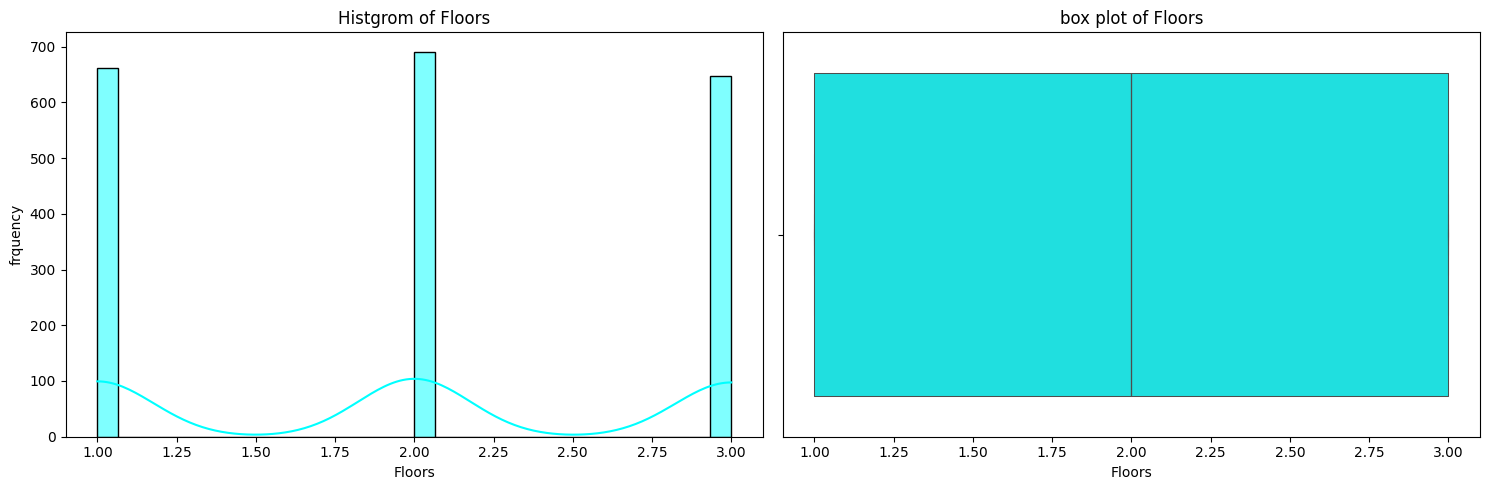

Number of Unique Floors: 3
Missing Values in Floors: 0


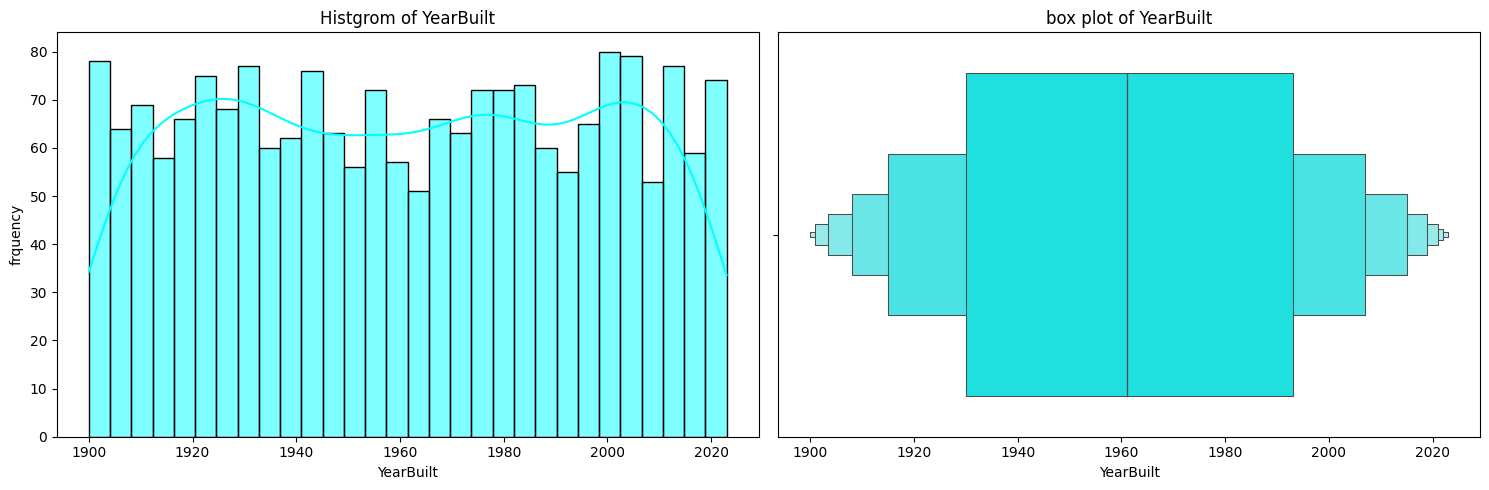

Number of Unique YearBuilt: 124
Missing Values in YearBuilt: 0


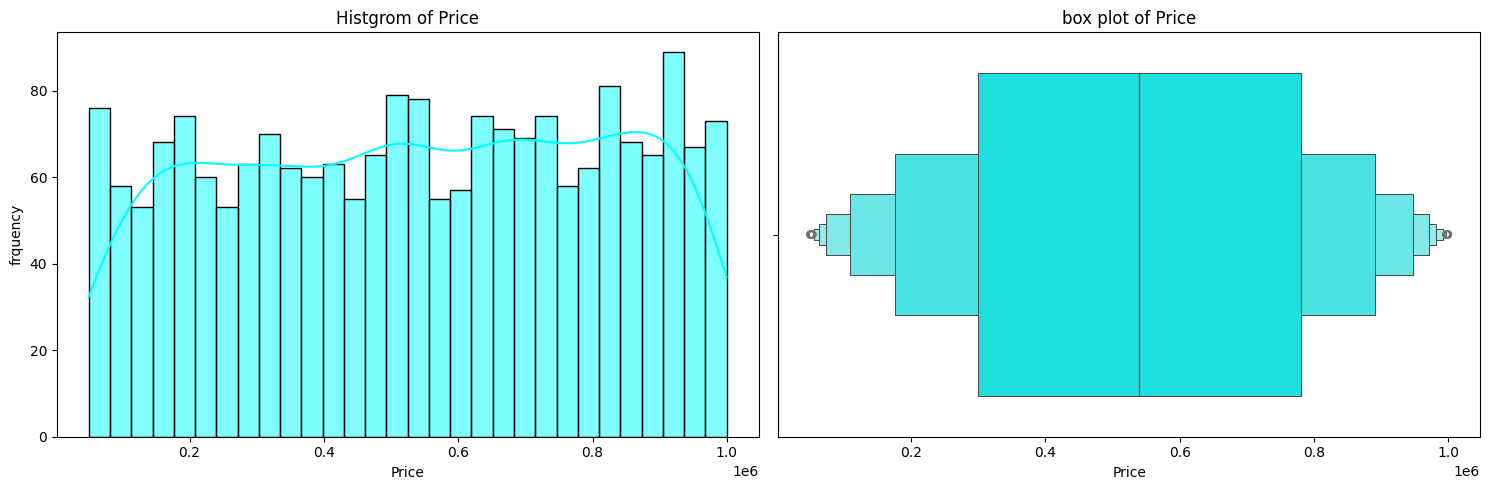

Number of Unique Price: 1999
Missing Values in Price: 0


In [ ]:
numerical = ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']

for col in numerical:
    plt.figure(figsize = (15,5))
    plt.subplot(1,2,1)
    sns.histplot(data = df, x = col, kde= True, bins = 30,color="cyan")
    plt.title(f"Histgrom of {col}")
    plt.xlabel(col)
    plt.ylabel("frquency")

    plt.subplot(1,2,2)
    sns.boxenplot(data = df, x=col, color ="cyan")
    plt.title(f"box plot of {col}")
    plt.tight_layout()
    plt.show()

        # Print unique and missing values
    print(f"Number of Unique {col}: {df[col].nunique()}")
    print(f"Missing Values in {col}: {df[col].isnull().sum()}")

# Categorical Features

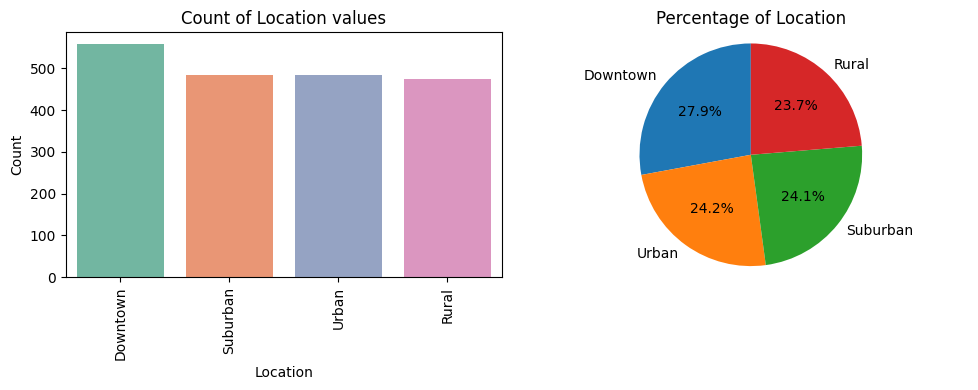

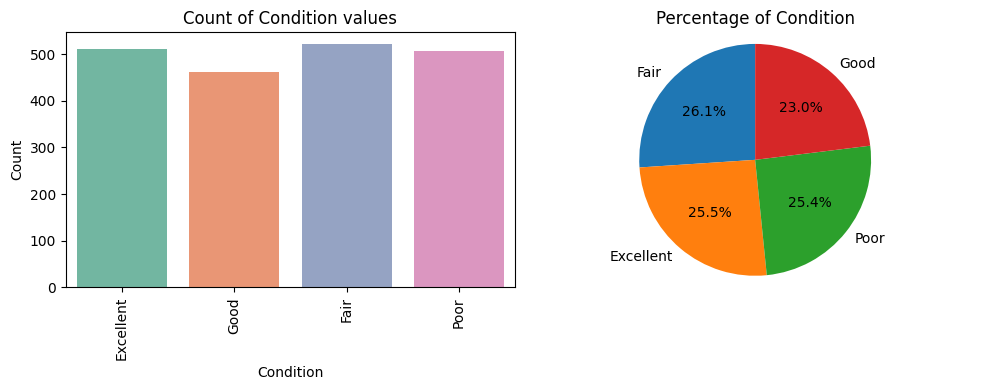

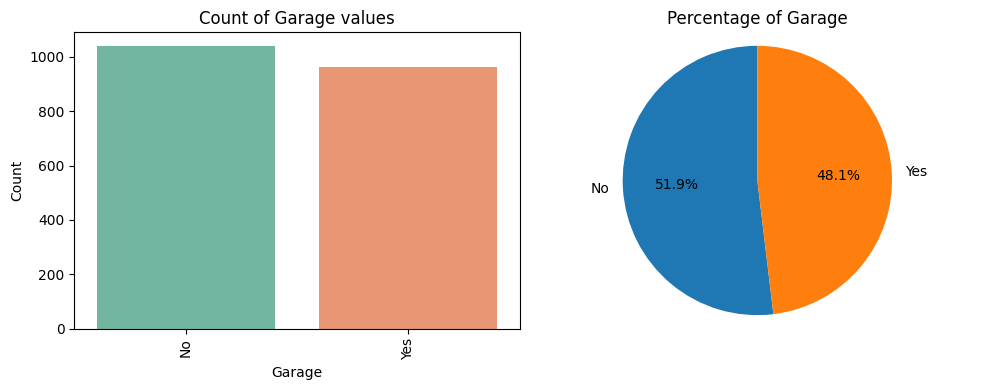

In [ ]:
for col in ['Location', 'Condition', 'Garage']:
    counts = df[col].value_counts()
    plt.figure(figsize = (10,4))
    plt.subplot(1,2,1)
    sns.countplot(data = df, x = col, palette = "Set2")
    plt.title(f"Count of {col} values")
    plt.xticks(rotation = 90)
    plt.ylabel("Count")
    # plt.show()

    plt.subplot(1,2,2)
    plt.pie(counts,labels = counts.index,autopct = "%1.1f%%",startangle=90)
    plt.title(f"Percentage of {col}")
    plt.axis('equal')
    plt.tight_layout()
    plt.show()


# Categorical Features vs Label

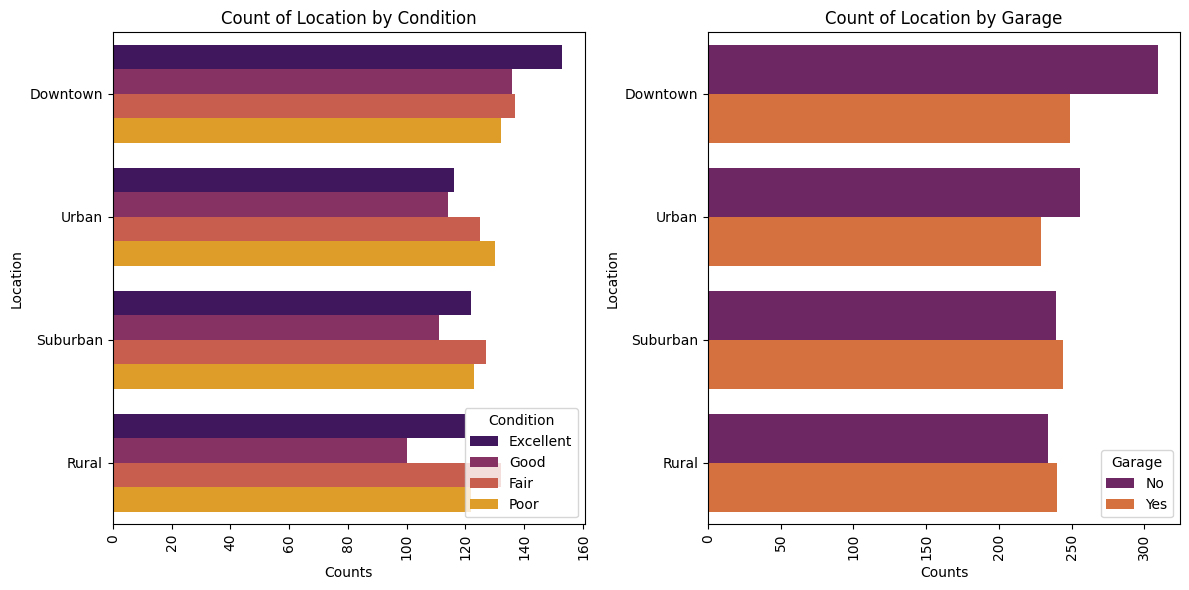

In [ ]:
# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Subplot 1: Count of Location by Condition
sns.countplot(data=df, y="Location", order=df["Location"].value_counts().index, hue="Condition", palette="inferno", ax=axs[0])
axs[0].set_title("Count of Location by Condition")
axs[0].set_xlabel("Counts")
axs[0].set_ylabel("Location")
axs[0].tick_params(axis='x', rotation=90)

# Subplot 2: Count of Location by Garage
sns.countplot(data=df, y="Location", order=df["Location"].value_counts().index, hue="Garage", palette="inferno", ax=axs[1])
axs[1].set_title("Count of Location by Garage")
axs[1].set_xlabel("Counts")
axs[1].set_ylabel("Location")
axs[1].tick_params(axis='x', rotation=90)

# Layout so plots do not overlap
fig.tight_layout()

plt.show()

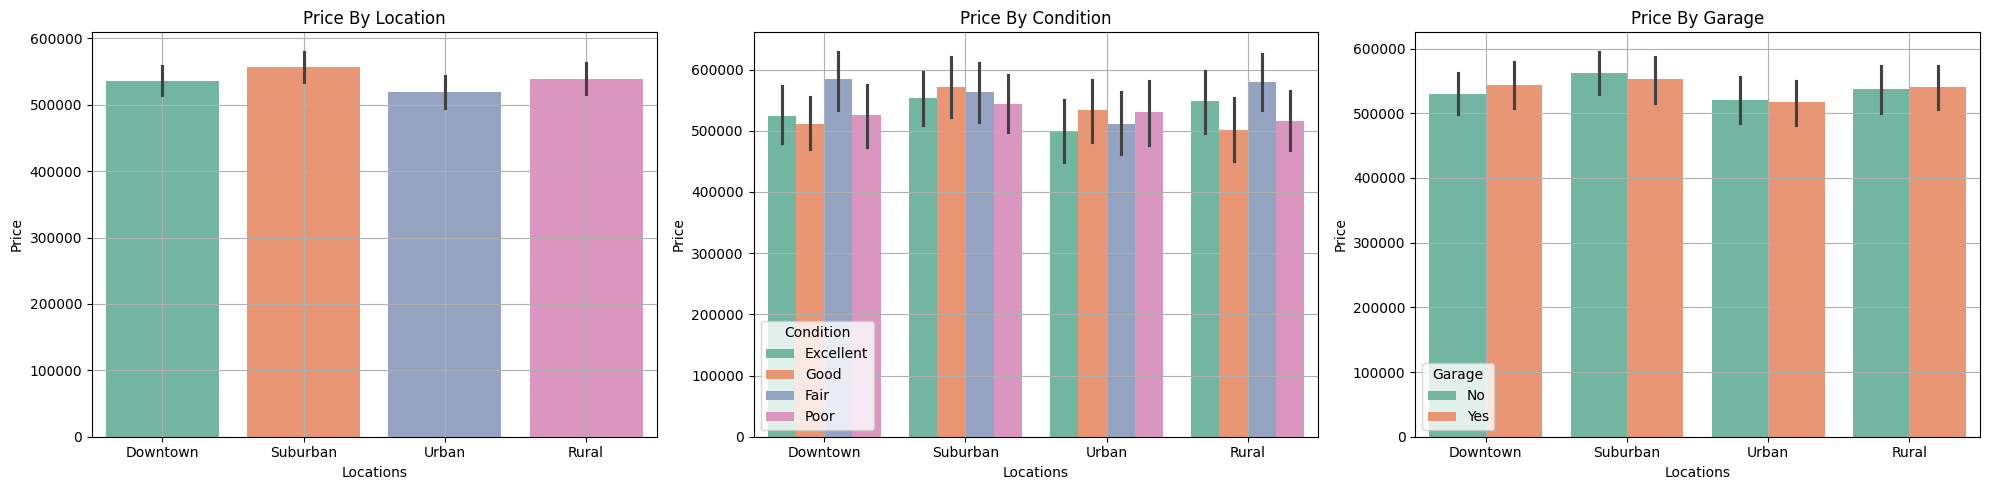

In [ ]:
plt.figure(figsize=(20,5))
plt.subplot(1,3,1)
sns.barplot(data=df, x="Location", y="Price", hue="Location", palette="Set2")
plt.title("Price By Location")
plt.xlabel("Locations")
plt.ylabel("Price")
plt.grid()

plt.subplot(1,3,2)
sns.barplot(data=df, x="Location", y="Price", hue="Condition", palette="Set2")
plt.title("Price By Condition")
plt.xlabel("Locations")
plt.ylabel("Price")
plt.grid()

plt.subplot(1,3,3)
sns.barplot(data=df, x="Location", y="Price", hue="Garage", palette="Set2")
plt.title("Price By Garage")
plt.xlabel("Locations")
plt.ylabel("Price")
plt.grid()

plt.tight_layout()
plt.show()

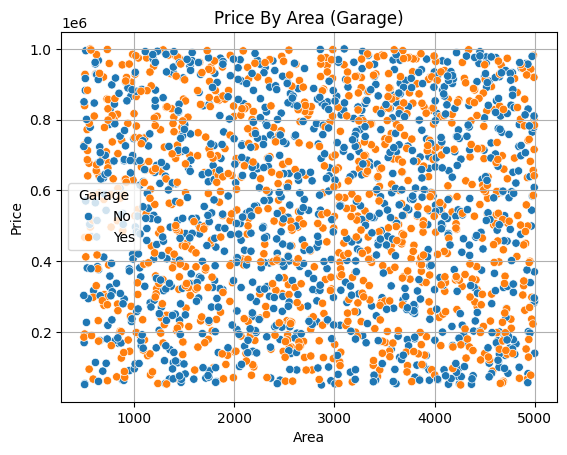

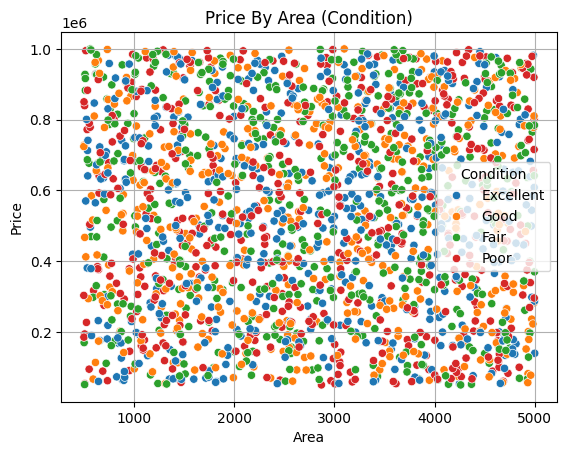

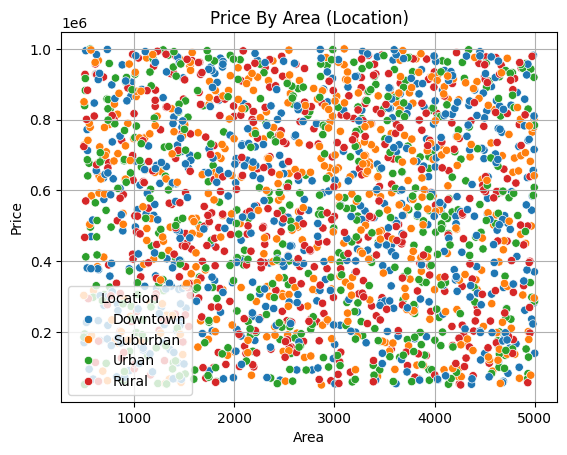

In [ ]:
# Scatter plot: Price by Area, colored by Garage
sns.scatterplot(data=df, x="Area", y="Price", color="violet", hue="Garage")
plt.title("Price By Area (Garage)")
plt.xlabel("Area")
plt.ylabel("Price")
plt.grid()
plt.show()

# Scatter plot: Price by Area, colored by Condition
sns.scatterplot(data=df, x="Area", y="Price", color="violet", hue="Condition")
plt.title("Price By Area (Condition)")
plt.xlabel("Area")
plt.ylabel("Price")
plt.grid()
plt.show()

# Scatter plot: Price by Area, colored by Location
sns.scatterplot(data=df, x="Area", y="Price", color="violet", hue="Location")
plt.title("Price By Area (Location)")
plt.xlabel("Area")
plt.ylabel("Price")
plt.grid()
plt.show()

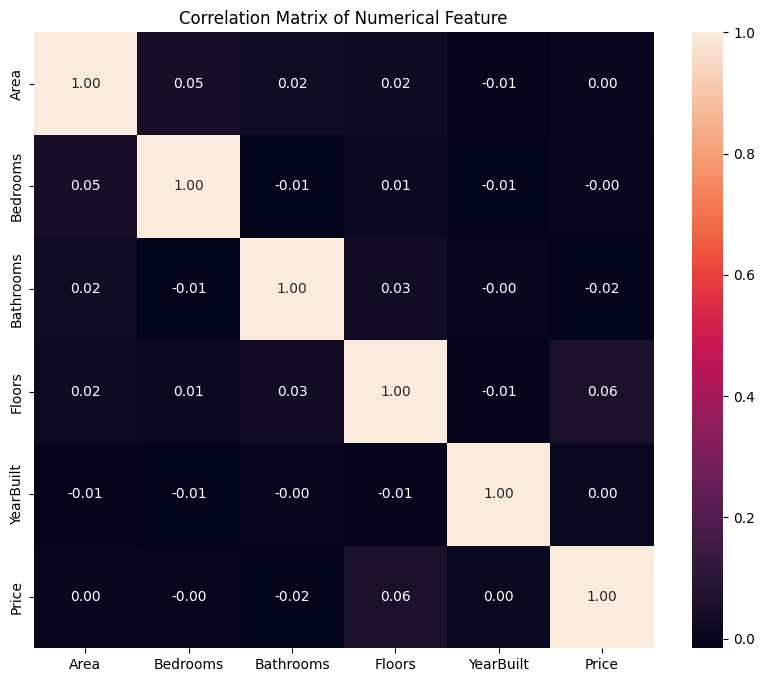

In [ ]:
correlatton_mat = df[numerical].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlatton_mat, annot = True ,fmt=".2f")
plt.title('Correlation Matrix of Numerical Feature')
plt.show()

# Model traning 🔧🧰 🤖🤖

In [ ]:
from sklearn.linear_model import LinearRegression

# Prepare features and target variable
X = df.drop(columns=['Price', 'Id'], errors='ignore')
y = df['Price']

# Split the dataset into training and validation sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Group feature columns by data types
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

# Create a column preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Build the Linear Regression pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model
lr_pipeline.fit(X_train, y_train)
print("Linear Regression Pipeline successfully built and trained!")

Linear Regression Pipeline successfully built and trained!


In [ ]:
# Evaluate the model
y_pred = lr_pipeline.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R-squared Score (R²):     {r2:.4f}")

Mean Squared Error (MSE): 78321466146.03
Mean Absolute Error (MAE): 243241.98
R-squared Score (R²):     -0.0067


### Comparative Model Performance Analysis
We will compare **Linear Regression**, a **Decision Tree**, and a **Random Forest** to evaluate if non-linear models perform any better on this dataset.

In [ ]:
# Define models to evaluate
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
}

results = []

# Loop through each model, train, predict, and calculate metrics
for name, model in models.items():
    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Train
    model_pipeline.fit(X_train, y_train)

    # Predict
    preds = model_pipeline.predict(X_test)

    # Evaluate
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, preds),
        'MSE': mean_squared_error(y_test, preds),
        'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
        'R2 Score': r2_score(y_test, preds)
    })

# Convert results to DataFrame for neat visualization
df_results = pd.DataFrame(results)
display(df_results.style.background_gradient(subset=['MAE', 'RMSE'], cmap='Reds').background_gradient(subset=['R2 Score'], cmap='Greens'))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,243241.977588,78321466146.032806,279859.725838,-0.006718
1,Decision Tree,249528.497466,84310896762.380356,290363.387434,-0.083704
2,Random Forest,245517.586798,79398355565.666367,281777.138117,-0.020560


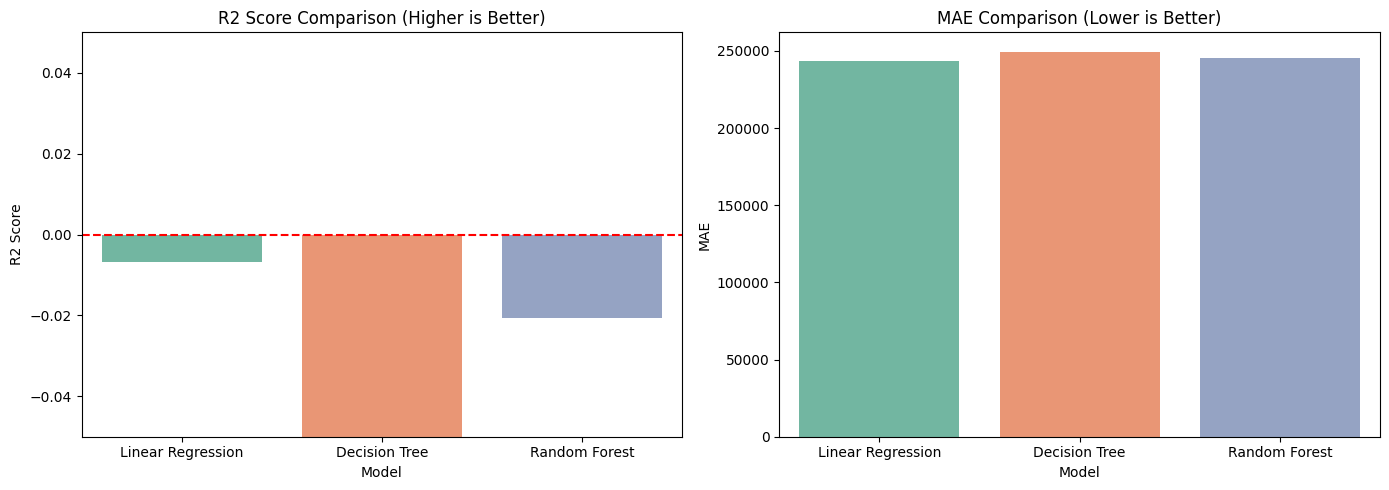

In [ ]:
# Visualize Model Comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot R2 Score
sns.barplot(data=df_results, x='Model', y='R2 Score', palette='Set2', ax=axes[0])
axes[0].set_title('R2 Score Comparison (Higher is Better)')
axes[0].set_ylim(-0.05, 0.05)
axes[0].axhline(0, color='red', linestyle='--')

# Plot MAE
sns.barplot(data=df_results, x='Model', y='MAE', palette='Set2', ax=axes[1])
axes[1].set_title('MAE Comparison (Lower is Better)')

plt.tight_layout()
plt.show()

### Results Interpretation & Presentation

* **Uniformly Poor Performance ($R^2 \approx 0$):** Regardless of using a linear model (Linear Regression) or robust non-linear models (Decision Tree & Random Forest), the $R^2$ score consistently hovers around `0` or slightly negative values.
* **Data Insight:** This proves that the features in this dataset (`Area`, `Bedrooms`, `Bathrooms`, `Floors`, `YearBuilt`, `Location`, `Condition`, `Garage`) share absolutely no predictive correlation with the target variable `Price`.
* **Conclusion:** The `Price` variable behaves as synthetic independent random noise or is completely unrelated to the house attributes provided, meaning no structural machine learning algorithm can model it effectively without additional features or different data.